In [1]:
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('base_vendas_voluntarios (1).csv')

In [3]:
df.head()

,Produto,Categoria do Produto,Preço,Frete,Data da Compra,Vendedor,Local da compra,Avaliação da compra,Tipo de pagamento,Quantidade de parcelas,lat,lon
0,Assistente virtual,eletronicos,219.08,9.249790,16/01/2021,Pedro Gomes,SP,4,cartao_credito,8,-22.19,-48.79
1,Mesa de jantar,moveis,256.35,11.234305,18/05/2022,Beatriz Moraes,RJ,1,cartao_credito,4,-22.25,-42.66
2,Jogo de tabuleiro,brinquedos,279.51,21.262681,15/03/2021,João Souza,DF,1,cartao_credito,1,-15.83,-47.86
3,Micro-ondas,eletrodomesticos,1009.99,54.667344,03/05/2022,João Souza,RS,4,boleto,1,-30.17,-53.50
4,Cadeira de escritório,moveis,446.99,26.964689,07/11/2020,Larissa Alves,MG,5,boleto,1,-18.10,-44.38


# %% 2. Visão geral da estrutura

In [6]:
# %% 2. Visão geral da estrutura
df["Data da Compra"] = pd.to_datetime(df["Data da Compra"], format="%d/%m/%Y")

print("Linhas x colunas:", df.shape)
print("\nTipos de dados:\n", df.dtypes)
print("\nValores nulos:\n", df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("\nPeríodo:", df["Data da Compra"].min().date(), "a", df["Data da Compra"].max().date())

Linhas x colunas: (2359, 12)

Tipos de dados:
 Produto                              str
Categoria do Produto                 str
Preço                            float64
Frete                            float64
Data da Compra            datetime64[us]
Vendedor                             str
Local da compra                      str
Avaliação da compra                int64
Tipo de pagamento                    str
Quantidade de parcelas             int64
lat                              float64
lon                              float64
dtype: object

Valores nulos:
 Produto                   0
Categoria do Produto      0
Preço                     0
Frete                     0
Data da Compra            0
Vendedor                  0
Local da compra           0
Avaliação da compra       0
Tipo de pagamento         0
Quantidade de parcelas    0
lat                       0
lon                       0
dtype: int64

Linhas duplicadas: 0

Período: 2020-01-01 a 2023-03-31


# %% 3. Quais colunas servem para cálculo financeiro?

In [7]:
numericas = df.select_dtypes("number").columns.tolist()
print("\nColunas numéricas:", numericas)
print(df[numericas].describe().T[["count", "mean", "min", "50%", "max"]])
 
mapa = pd.DataFrame(
    [
        ("Preço",                  "Financeira",  "Base do faturamento"),
        ("Frete",                  "Financeira",  "Custo/receita de entrega; compõe o valor total pago"),
        ("Quantidade de parcelas", "Financeira",  "Fluxo de caixa: valor da parcela e prazo de recebimento"),
        ("Tipo de pagamento",      "Apoio",       "Mix de pagamento; só cartão de crédito parcela"),
        ("Data da Compra",         "Apoio",       "Evolução mensal/anual, crescimento, sazonalidade"),
        ("Categoria do Produto",   "Segmentação", "Faturamento por categoria"),
        ("Produto",                "Segmentação", "Faturamento por produto"),
        ("Local da compra",        "Segmentação", "Faturamento por UF"),
        ("Vendedor",               "Segmentação", "Faturamento por vendedor"),
        ("Avaliação da compra",    "Qualitativa", "Não é financeira; cruzar com faturamento"),
        ("lat / lon",              "Descartar",   "Só para mapas"),
    ],
    columns=["Coluna", "Papel", "Uso"],
)
print("\n", mapa.to_string(index=False))


Colunas numéricas: ['Preço', 'Frete', 'Avaliação da compra', 'Quantidade de parcelas', 'lat', 'lon']
                         count        mean    min         50%         max
Preço                   2359.0  650.491361  10.07  313.750000  3969.38000
Frete                   2359.0   34.691805   0.00   16.498835   214.37706
Avaliação da compra     2359.0    3.976685   1.00    5.000000     5.00000
Quantidade de parcelas  2359.0    2.943196   1.00    1.000000    24.00000
lat                     2359.0  -20.763366 -30.17  -22.190000     1.41000
lon                     2359.0  -47.349385 -70.55  -48.790000   -36.59000

                 Coluna       Papel                                                     Uso
                 Preço  Financeira                                     Base do faturamento
                 Frete  Financeira     Custo/receita de entrega; compõe o valor total pago
Quantidade de parcelas  Financeira Fluxo de caixa: valor da parcela e prazo de recebimento
     Tipo de p

# %% 4. Colunas calculadas

In [9]:
df["Valor Total"] = df["Preço"] + df["Frete"]            # o que o cliente paga
df["Frete %"] = df["Frete"] / df["Preço"] * 100            # peso do frete
# Premissa: parcelas iguais e sem juros (a base não informa juros)
df["Valor da Parcela"] = df["Valor Total"] / df["Quantidade de parcelas"]
df["Ano"] = df["Data da Compra"].dt.year
df["Mês"] = df["Data da Compra"].dt.to_period("M")

# %% 5. Indicadores financeiros gerais

In [11]:
faturamento = df["Preço"].sum()
frete_total = df["Frete"].sum()
n_vendas = len(df)
 
kpis = {
    "Total de vendas": n_vendas,
    "Faturamento (Preço)": faturamento,
    "Frete total": frete_total,
    "Valor total (Preço + Frete)": df["Valor Total"].sum(),
    "Ticket médio": faturamento / n_vendas,
    "Ticket mediano": df["Preço"].median(),
    "Frete médio % do preço": df["Frete %"].mean(),
    "Parcelas médias (crédito)": df.loc[df["Tipo de pagamento"] == "cartao_credito",
                                        "Quantidade de parcelas"].mean(),
}
print("\nKPIs")
for k, v in kpis.items():
    print(f"  {k:32s} {v:,.2f}")


KPIs
  Total de vendas                  2,359.00
  Faturamento (Preço)              1,534,509.12
  Frete total                      81,837.97
  Valor total (Preço + Frete)      1,616,347.09
  Ticket médio                     650.49
  Ticket mediano                   313.75
  Frete médio % do preço           5.52
  Parcelas médias (crédito)        3.69


# %% 6. Faturamento por dimensão

In [12]:
def resumo(coluna):
    t = df.groupby(coluna).agg(
        vendas=("Preço", "size"),
        faturamento=("Preço", "sum"),
        ticket_medio=("Preço", "mean"),
        frete=("Frete", "sum"),
        avaliacao=("Avaliação da compra", "mean"),
    )
    t["% do faturamento"] = t["faturamento"] / faturamento * 100
    return t.sort_values("faturamento", ascending=False).round(2)
 
for col in ["Categoria do Produto", "Tipo de pagamento", "Local da compra", "Vendedor", "Ano"]:
    print(f"\n--- Por {col} ---")
    print(resumo(col).head(10))
 
print("\n--- Top 10 produtos por faturamento ---")
print(resumo("Produto").head(10))


--- Por Categoria do Produto ---
                       vendas  faturamento  ticket_medio     frete  avaliacao  \
Categoria do Produto                                                            
eletronicos               448    572659.23       1278.26  30619.01       4.00   
eletrodomesticos          312    484913.36       1554.21  25764.96       4.03   
moveis                    465    250178.11        538.02  13327.21       3.95   
instrumentos musicais     182    121731.69        668.86   6511.81       4.05   
esporte e lazer           284     52387.55        184.46   2829.11       3.90   
brinquedos                324     23993.78         74.05   1305.49       4.08   
utilidades domesticas     171     16931.48         99.01    857.90       3.75   
livros                    173     11713.92         67.71    622.49       3.98   

                       % do faturamento  
Categoria do Produto                     
eletronicos                       37.32  
eletrodomesticos             

# %% 7. Evolução no tempo e crescimento
# ATENÇÃO: 2023 vai só até março (ano parcial) — não compare com anos fechados.

In [13]:
anual = df.groupby("Ano")["Preço"].sum()
cresc = anual.pct_change() * 100
print("\nFaturamento anual:\n", anual.round(2))
print("\nCrescimento anual %:\n", cresc.round(2))
 
# Comparação justa: jan–mar de cada ano
jan_mar = df[df["Data da Compra"].dt.month <= 3].groupby("Ano")["Preço"].sum()
print("\nFaturamento jan–mar por ano:\n", jan_mar.round(2))
 
mensal = df.groupby("Mês")["Preço"].sum()


Faturamento anual:
 Ano
2020    491911.51
2021    482829.91
2022    422086.24
2023    137681.46
Name: Preço, dtype: float64

Crescimento anual %:
 Ano
2020      NaN
2021    -1.85
2022   -12.58
2023   -67.38
Name: Preço, dtype: float64

Faturamento jan–mar por ano:
 Ano
2020    139601.26
2021    116693.56
2022    105866.59
2023    137681.46
Name: Preço, dtype: float64


# %% 8. Parcelamento (impacto no fluxo de caixa)

In [14]:
credito = df[df["Tipo de pagamento"] == "cartao_credito"]
print("\nDistribuição de parcelas (crédito):")
print(credito["Quantidade de parcelas"].value_counts().sort_index())
print("\nValor da parcela médio:", round(credito["Valor da Parcela"].mean(), 2))
print("% do faturamento parcelado em 2x ou mais:",
      round(df.loc[df["Quantidade de parcelas"] > 1, "Preço"].sum() / faturamento * 100, 1))


Distribuição de parcelas (crédito):
Quantidade de parcelas
1     549
2     257
3     229
4     147
5     131
6      86
7      40
8      96
9      11
10    142
11      2
12     10
14      2
18      1
24      1
Name: count, dtype: int64

Valor da parcela médio: 348.74
% do faturamento parcelado em 2x ou mais: 50.2


# %% 9. Qualidade para uso financeiro: outliers de preço (método IQR)

In [15]:
q1, q3 = df["Preço"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
outliers = df[df["Preço"] > lim_sup]
print(f"\nPreços acima de {lim_sup:,.2f}: {len(outliers)} vendas "
      f"({outliers['Preço'].sum() / faturamento * 100:.1f}% do faturamento)")
print(outliers.groupby("Categoria do Produto")["Preço"].agg(["count", "sum"]).round(2))
print("Preços <= 0:", (df["Preço"] <= 0).sum(), "| Fretes negativos:", (df["Frete"] < 0).sum())


Preços acima de 2,148.81: 168 vendas (31.8% do faturamento)
                      count        sum
Categoria do Produto                  
eletrodomesticos         50  141394.52
eletronicos             118  345823.86
Preços <= 0: 0 | Fretes negativos: 0


# %% 10. Gráficos

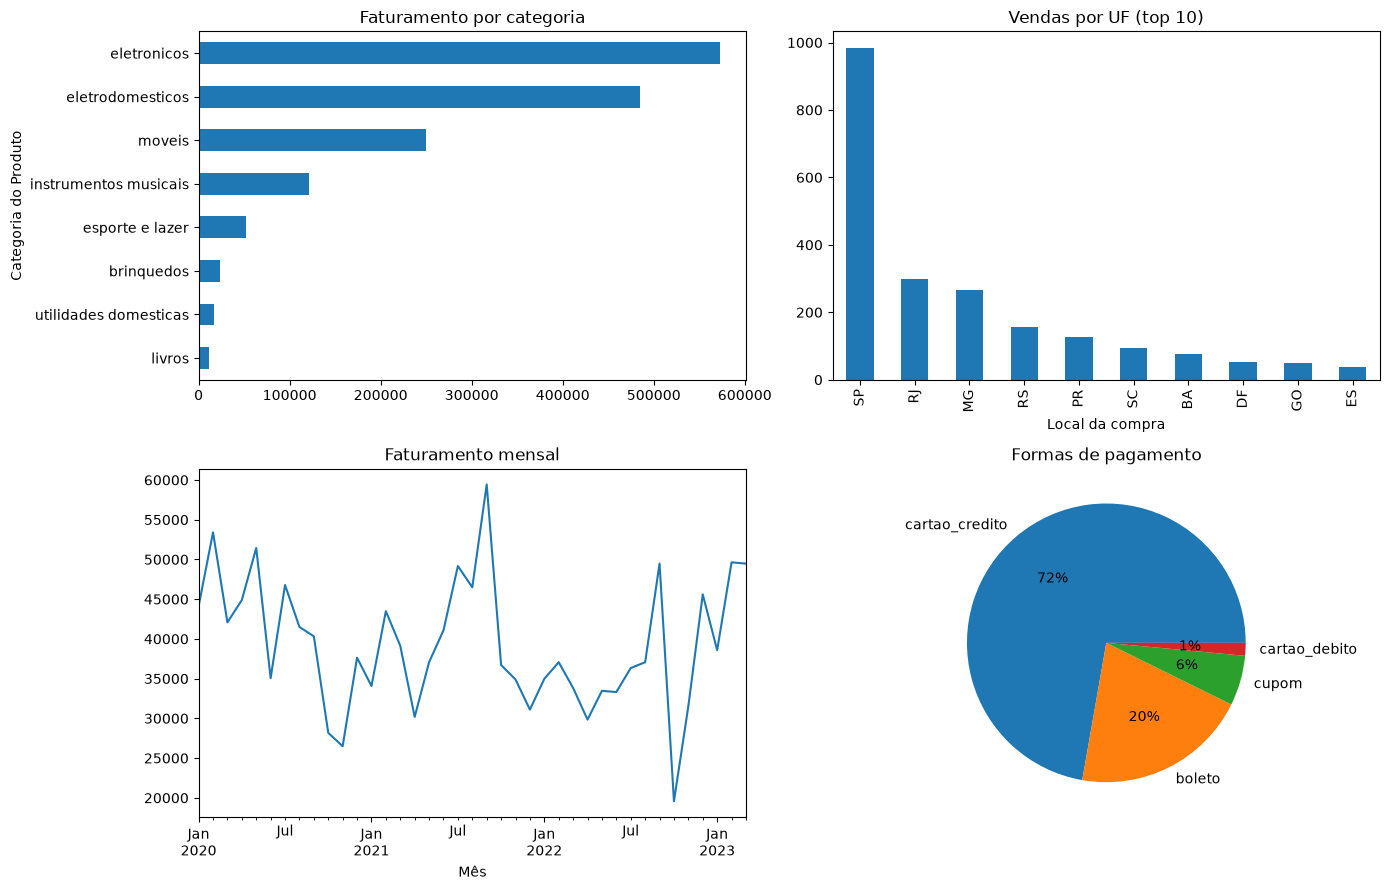

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
df.groupby("Categoria do Produto")["Preço"].sum().sort_values().plot.barh(ax=ax[0, 0], title="Faturamento por categoria")
df.groupby("Local da compra")["Preço"].size().sort_values(ascending=False).head(10).plot.bar(ax=ax[0, 1], title="Vendas por UF (top 10)")
mensal.plot(ax=ax[1, 0], title="Faturamento mensal")
df["Tipo de pagamento"].value_counts().plot.pie(ax=ax[1, 1], autopct="%1.0f%%", ylabel="", title="Formas de pagamento")
plt.tight_layout(); plt.show()

 # Categoria com maior faturamento

In [19]:
fat_cat = df.groupby("Categoria do Produto")["Preço"].sum().sort_values(ascending=False)
print(f"\n1) Maior faturamento: {fat_cat.index[0]} — R$ {fat_cat.iloc[0]:,.2f} "
      f"({fat_cat.iloc[0] / fat_cat.sum():.1%} do total)")
print(fat_cat)


1) Maior faturamento: eletronicos — R$ 572,659.23 (37.3% do total)
Categoria do Produto
eletronicos              572659.23
eletrodomesticos         484913.36
moveis                   250178.11
instrumentos musicais    121731.69
esporte e lazer           52387.55
brinquedos                23993.78
utilidades domesticas     16931.48
livros                    11713.92
Name: Preço, dtype: float64


 # Estado com mais vendas

In [20]:
vendas_uf = df["Local da compra"].value_counts()
print(f"\n2) Estado com mais vendas: {vendas_uf.index[0]} — {vendas_uf.iloc[0]} vendas "
      f"({vendas_uf.iloc[0] / len(df):.1%})")
print(vendas_uf.head(5))


2) Estado com mais vendas: SP — 984 vendas (41.7%)
Local da compra
SP    984
RJ    298
MG    265
RS    155
PR    128
Name: count, dtype: int64


# Produto mais vendidos

In [21]:
vendas_prod = df["Produto"].value_counts()
campeoes = vendas_prod[vendas_prod == vendas_prod.max()].index.tolist()
print(f"\n3) Produto(s) mais vendido(s) ({vendas_prod.max()} vendas cada): {campeoes}")
print("Maior faturamento:", df.groupby("Produto")["Preço"].sum().idxmax())


3) Produto(s) mais vendido(s) (60 vendas cada): ['Micro-ondas', 'TV Led UHD 4K', 'Guarda roupas']
Maior faturamento: TV Led UHD 4K


# Forma de pagamento mais usada 

In [22]:
pagto = df["Tipo de pagamento"].value_counts()
print(f"\n4) Forma de pagamento mais usada: {pagto.index[0]} — {pagto.iloc[0]} vendas "
      f"({pagto.iloc[0] / len(df):.1%})")
print(pagto)


4) Forma de pagamento mais usada: cartao_credito — 1704 vendas (72.2%)
Tipo de pagamento
cartao_credito    1704
boleto             483
cupom              137
cartao_debito       35
Name: count, dtype: int64


# Volume de vendas ao longo dos anos

In [23]:
anos = df.groupby("Ano").agg(vendas=("Preço", "size"),
                             faturamento=("Preço", "sum"),
                             ticket_medio=("Preço", "mean"),
                             meses=("Mês", "nunique"))
anos["vendas_por_mes"] = anos["vendas"] / anos["meses"]
print("\n5) Vendas por ano:")
print(anos)


5) Vendas por ano:
      vendas  faturamento  ticket_medio  meses  vendas_por_mes
Ano                                                           
2020     715    491911.51    687.988126     12       59.583333
2021     739    482829.91    653.355765     12       61.583333
2022     713    422086.24    591.986311     12       59.416667
2023     192    137681.46    717.090937      3       64.000000


# Categoria com menor avaliação média

In [24]:
aval = df.groupby("Categoria do Produto")["Avaliação da compra"].mean().sort_values()
print(f"\n6) Menor avaliação média: {aval.index[0]} — nota {aval.iloc[0]:.2f}")
print(aval)


6) Menor avaliação média: utilidades domesticas — nota 3.75
Categoria do Produto
utilidades domesticas    3.748538
esporte e lazer          3.897887
moveis                   3.946237
livros                   3.976879
eletronicos              4.004464
eletrodomesticos         4.032051
instrumentos musicais    4.049451
brinquedos               4.077160
Name: Avaliação da compra, dtype: float64


 # Graficos 

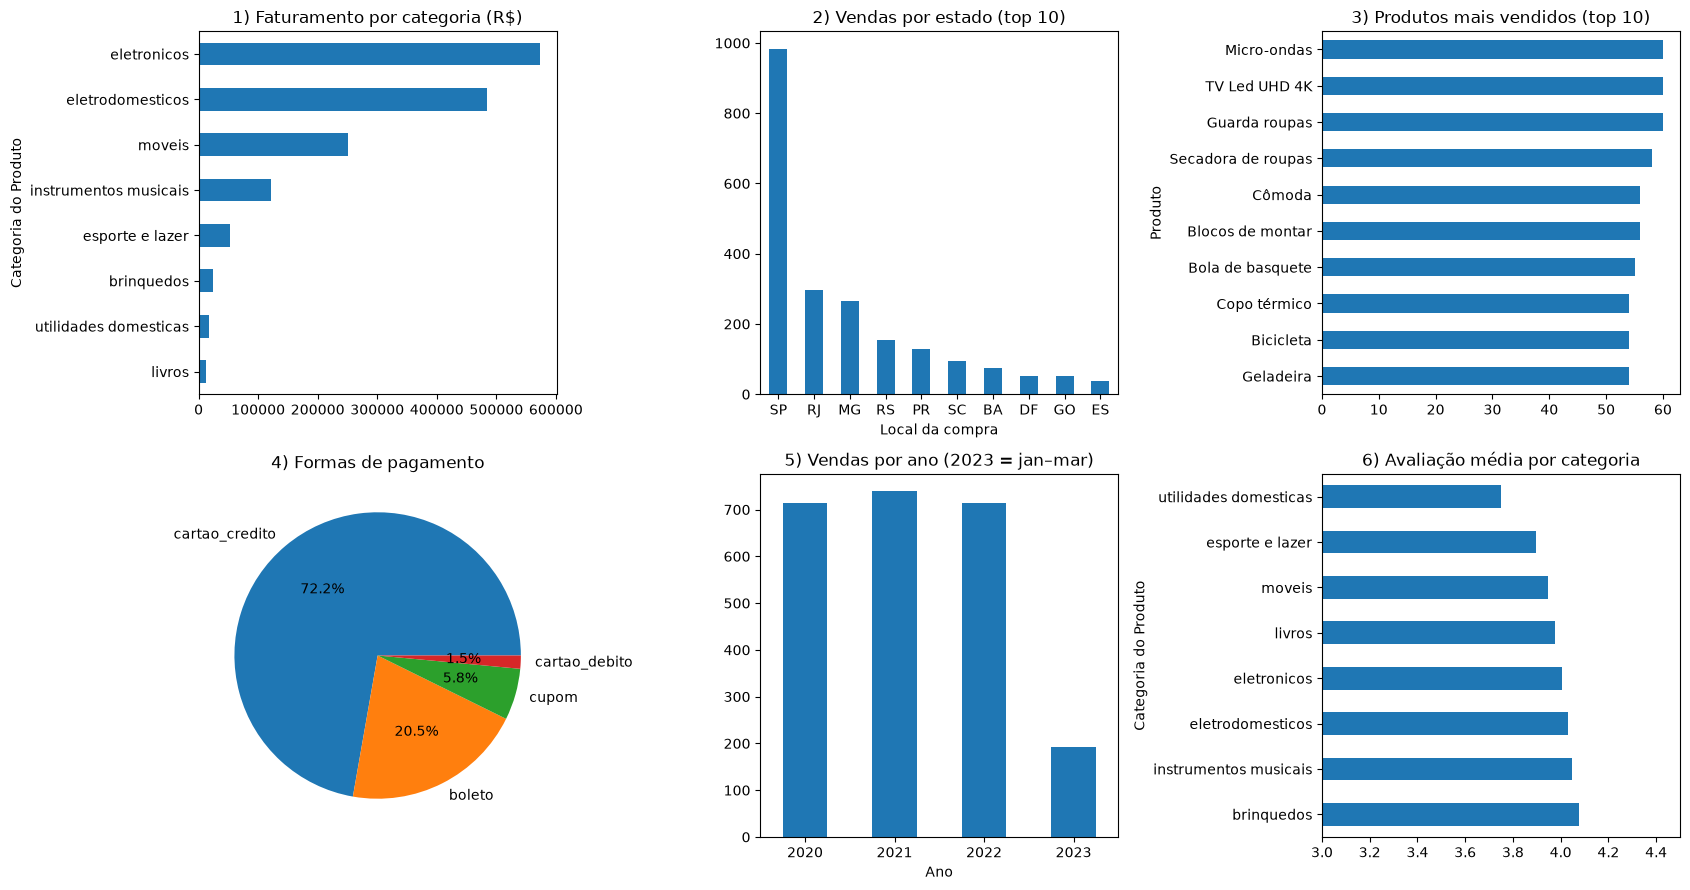

In [25]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
fat_cat.sort_values().plot.barh(ax=ax[0, 0], title="1) Faturamento por categoria (R$)")
vendas_uf.head(10).plot.bar(ax=ax[0, 1], title="2) Vendas por estado (top 10)", rot=0)
vendas_prod.head(10).sort_values().plot.barh(ax=ax[0, 2], title="3) Produtos mais vendidos (top 10)")
pagto.plot.pie(ax=ax[1, 0], autopct="%1.1f%%", ylabel="", title="4) Formas de pagamento")
anos["vendas"].plot.bar(ax=ax[1, 1], title="5) Vendas por ano (2023 = jan–mar)", rot=0)
aval.sort_values(ascending=False).plot.barh(ax=ax[1, 2], title="6) Avaliação média por categoria")
ax[1, 2].set_xlim(3, 4.5)
plt.tight_layout()
plt.show()

## Conclusão do projeto

Este projeto analisou **2.359 vendas** realizadas entre janeiro de 2020 e março de 2023, que somam **R$ 1,53 milhão** em faturamento, considerando apenas o valor dos produtos, sem o frete. O trabalho percorreu todas as etapas pedidas no laboratório: preparação e verificação da base, resposta a seis perguntas de negócio, construção de um dashboard e replicação das análises em Python. A principal conclusão é que o negócio mantém um volume de vendas estável, mas ganha pouco por venda e depende de poucas categorias, de poucos estados e de poucos produtos de preço alto.

### Pontos positivos

O ponto mais evidente é a força de **eletrônicos e eletrodomésticos**, que geram 68,9% do faturamento com apenas 32% das vendas, graças a um ticket médio elevado. O volume mensal também se mostrou estável, em torno de 60 vendas por mês durante todo o período, e o primeiro trimestre de 2023 trouxe sinais de recuperação: o faturamento chegou a R$ 137,7 mil, cerca de 30% acima do mesmo período de 2022, impulsionado principalmente pelos eletrônicos. Os clientes, em geral, estão satisfeitos, com nota média de 3,98 em 5 e mais da metade das avaliações em nota máxima. O cartão de crédito, usado em 72% das vendas, facilita a compra sem encarecer o ticket, e a base de dados se mostrou confiável, sem valores vazios, duplicatas ou preços inválidos.

### Pontos negativos

O faturamento caiu cerca de **14% entre 2020 e 2022**, e essa queda veio da redução do ticket médio, de R$ 688 para R$ 592, já que a quantidade de vendas permaneceu igual. A operação também é muito concentrada: São Paulo responde por 41,7% das vendas e, junto com Rio de Janeiro e Minas Gerais, chega a 65,6%. Categorias como livros, utilidades domésticas e brinquedos representam 28% das vendas, mas apenas 3,4% da receita. Utilidades domésticas ainda apresenta a menor nota média, 3,75, e a maior proporção de avaliações baixas, 24% contra 15% a 18% nas demais categorias, o que sugere um problema de qualidade a investigar. Além disso, o parcelamento médio de 3,7 vezes no cartão de crédito alonga o recebimento e pesa no fluxo de caixa. A própria base impõe limites, pois não traz custo, desconto nem juros, o que impede calcular lucro ou margem, e 2023 tem apenas três meses de dados.

### Aprendizados

O projeto mostrou que **volume de vendas e faturamento contam histórias diferentes**: móveis lidera em quantidade, mas eletrônicos lidera em receita, e olhar só uma das medidas leva a conclusões equivocadas. Também ficou claro que comparar um ano parcial com anos completos distorce a leitura, e que a comparação justa é feita entre os mesmos meses de cada ano. Outro aprendizado foi tratar empates como resultado, já que três produtos tiveram 60 vendas cada, e registrar as premissas por escrito, como a definição de faturamento. No método, conferir o Excel contra o pandas permitiu encontrar e corrigir um erro no gráfico de estados, que estava ordenado por faturamento em vez de vendas, e manter as tabelas ligadas à base por fórmulas garante que o dashboard se atualize quando os dados mudarem. No plano técnico, o projeto consolidou o uso de `SUMIFS`, `COUNTIFS` e `AVERAGEIFS` no Excel, de `groupby` e `value_counts` no pandas e a construção de gráficos nas duas ferramentas.

### Próximos passos

Recomenda-se entender o que provocou a queda do ticket médio entre 2020 e 2022, reduzir a dependência de São Paulo e do Sudeste, investigar as notas baixas de utilidades domésticas, acompanhar os meses seguintes de 2023 para confirmar a recuperação e incluir custos e descontos na base, de modo a analisar lucro e margem e não apenas faturamento.